<div style="background-color: black; color: white; padding: 10px;text-align: center;">
  <strong>Date Published:</strong> Oct 18, 2026 <strong>Author:</strong> Adnan Alaref
</div>

# **Step 1: Import Library.**

In [1]:
import torch

print(torch.__version__)
print(torch.version.cuda)
print(torch.cuda.get_device_name(0))
print(torch.cuda.get_device_capability(0))

2.11.0+cu128
12.8
Tesla T4
(7, 5)


In [2]:
import numpy as np
import pandas as pd
import seaborn as sns

print(np.__version__)
print(pd.__version__)
print(sns.__version__)

2.1.3
2.3.3
0.13.2


In [3]:
import re
import os
import cv2
import random
import torch.nn as nn
import matplotlib.pyplot as plt
import torchvision.models as models
import torchvision.transforms.v2 as v2


from pathlib import Path
from pprint import pprint
from tqdm.auto import tqdm
from PIL import Image, ImageOps
from collections import Counter
from torch.cuda.amp import autocast
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import f1_score, classification_report
from typing import Dict, List, TypeVar, Tuple, Any, Callable, Optional

import warnings
warnings.simplefilter(action='ignore')
warnings.filterwarnings(action='ignore', category=FutureWarning)

# **Step 2: Collect Player Temporal Data From Clips With 9 Frames Include Middle Image.**

In [4]:
dataset_root = r"/kaggle/input/datasets/sherif31/group-activity-recognition-volleyball"

In [5]:
from collections import OrderedDict
from dataclasses import dataclass

# ── Data structure for a single player's temporal sequence ─
@dataclass
class PlayerInfo:
  player_id: int
  player_action: str
  frame_paths: List[Path]
  player_boxes : List[Tuple[int, int, int, int]]

# ── Collect player's temporal sequences from the dataset ───
def collect_player_temporal_sequences(dataset_root: str,
                                      split_group:List[int])-> OrderedDict[Tuple[int, int ,int], PlayerInfo]:
  """
    Collect 9-frame temporal sequences for each player in the given videos.

    For each annotated clip, the function collects the player's bounding boxes
    from four frames before the target frame through four frames after it.
    The player's action is taken from the target frame.

    Args:
        dataset_root: Root directory of the volleyball dataset.
        split_group: List of video IDs to process.

    Returns:
        An OrderedDict mapping (video_id, clip_id, player_id) tuples
        to PlayerInfo objects.
  """

  player_sequences: OrderedDict[Tuple[int, int ,int], PlayerInfo] = OrderedDict()

  videos_root = os.path.join(dataset_root, "videos")
  videos_tracking_root = os.path.join(dataset_root,"volleyball_tracking_annotation")

  # ── Iterate over videos in the requested split ───
  for video_id in split_group:

    # Path to annotations.txt for the current video
    video_annot = os.path.join(videos_root, str(video_id), 'annotations.txt')
    if not os.path.isfile(video_annot):
      raise FileNotFoundError(f"Video annotation file does not exist.: \
                              \nPath: {video_annot}")

    # ── Read each annotated clip ───
    with open(file= video_annot, mode='r') as file_annot:
      for annot_line in file_annot:
        clip_id = int(annot_line.partition(".")[0])

        path = Path(videos_root, str(video_id), str(clip_id))
        video_track_annotation = os.path.join(videos_tracking_root, str(video_id)
                                                 ,str(clip_id), f"{clip_id}.txt")

        begin_frame = clip_id - 4
        end_frame = clip_id + 4
        selected_frames = [frame for frame in range(begin_frame, end_frame + 1)]

        current_player_id = None
        player_action = None
        player_boxes: List[Tuple[int, int, int, int]] = []

        # ── Read tracking annotations for the current clip ─
        with open(file= video_track_annotation, mode='r') as file_tracker:
          # 0 31 386 85 511 13276 0 0 0 standing
          for tracker_line in file_tracker:

            parts = tracker_line.strip().split(" ")
            player_id = int(parts[0])
            frame_id = int(parts[5])

            # ── Detect a new player ───
            if current_player_id is None:
              current_player_id = player_id


            elif player_id != current_player_id:

              # ── Save previous player ─────
              player_sequences[(video_id, clip_id, current_player_id)] = PlayerInfo(
                player_id= current_player_id,
                player_action= player_action,
                frame_paths=[
                  path / f"{frame}.jpg"
                  for frame in selected_frames
                ],
                player_boxes= player_boxes
              )

              # ── Start new player ──
              current_player_id = player_id
              player_action = None
              player_boxes = []

            # ── Collect only the 9 temporal frames ─────
            if begin_frame <= frame_id <= end_frame:
              bbox = tuple(map(int, parts[1:5]))
              player_boxes.append(bbox)

              if frame_id == clip_id:
                player_action  = parts[-1] # parts[9]

          # ── Save the last player ───
          player_sequences[(video_id, clip_id, current_player_id)] = PlayerInfo(
            player_id= current_player_id,
            player_action= player_action,
            frame_paths=[
              path / f"{frame}.jpg"
              for frame in selected_frames
            ],
            player_boxes= player_boxes
          )

  return player_sequences

In [6]:
df = collect_player_temporal_sequences(dataset_root, [0])
pprint(df[(0,13286,0)])

PlayerInfo(player_id=0,
           player_action='standing',
           frame_paths=[PosixPath('/kaggle/input/datasets/sherif31/group-activity-recognition-volleyball/videos/0/13286/13282.jpg'),
                        PosixPath('/kaggle/input/datasets/sherif31/group-activity-recognition-volleyball/videos/0/13286/13283.jpg'),
                        PosixPath('/kaggle/input/datasets/sherif31/group-activity-recognition-volleyball/videos/0/13286/13284.jpg'),
                        PosixPath('/kaggle/input/datasets/sherif31/group-activity-recognition-volleyball/videos/0/13286/13285.jpg'),
                        PosixPath('/kaggle/input/datasets/sherif31/group-activity-recognition-volleyball/videos/0/13286/13286.jpg'),
                        PosixPath('/kaggle/input/datasets/sherif31/group-activity-recognition-volleyball/videos/0/13286/13287.jpg'),
                        PosixPath('/kaggle/input/datasets/sherif31/group-activity-recognition-volleyball/videos/0/13286/13288.jpg'),
        

# **Step 3: Create Custom Dateset.**

In [7]:
from functools import lru_cache

"""
Volleyball Player Temporal Sequence Dataset.

This module provides a PyTorch Dataset implementation for loading and processing
9-frame temporal sequences of individual volleyball players (4 frames before,
the target frame, and 4 frames after).

It features:
    - An LRU-cached image loader (`load_image_cached`) to minimize redundant disk
      I/O and image decoding overhead for players sharing the same video clips.
    - `PlayerTemporalSequenceDataset`: Custom PyTorch Dataset that handles player bounding
      box cropping, temporal transformations or default torchvision v2 processing,
      and label mappings.
    - Summary and debug utilities for dataset inspection.
"""

@lru_cache(maxsize=200)
def load_image_cached(frame_path_str: str) -> Image.Image:
  try:
    with Image.open(frame_path_str) as image:
      image = ImageOps.exif_transpose(image)
      return image.convert("RGB")

  except Exception as e:
    raise RuntimeError(f"Failed to load image: {frame_path_str}") from e


class PlayerTemporalSequenceDataset(Dataset):
  # Fixed classes list
  PLAYER_ACTIVITY_CLASSES = ["standing", "moving", "waiting", "blocking",
                               "digging", "setting", "falling", "spiking", "jumping"
  ]

  def __init__(self, player_sequences: OrderedDict[Tuple[int, int, int], PlayerInfo], transform = None, debug:bool = False)->None:
    super().__init__()


    # ── Store dataset configuration ────
    self.debug = debug
    self.transform = transform

    # Each sample represents one player with 9 frames.
    self.samples = list(player_sequences.values())

    # ── Count all temporal crops across all players ──────
    # Each player contributes 9 crops: 4 frames before + target + 4 after.
    self.num_crops = sum(
      len(player_info.player_boxes)
      for player_info in self.samples
    )

    # ── Create player activity ↔ index mappings ───────
    self.player_action2idx = {action:idx for idx, action in enumerate(self.PLAYER_ACTIVITY_CLASSES)}
    self.player_idx2action = {idx:action for action , idx in self.player_action2idx.items()}

    # Pre-convert labels to tensor for efficiency
    self.labels = torch.tensor([
      self.player_action2idx[player_info.player_action] for player_info in self.samples],
      dtype=torch.long
    )

  def __len__(self)->int:
    """Return the number of player temporal sequence."""
    return len(self.samples)

  def __getitem__(self, index)->Optional[Tuple[torch.Tensor, torch.Tensor]]:

    # ── Get one group sample ───
    player_info = self.samples[index]
    player_crops:List[Image.Image] = []

    assert len(player_info.frame_paths) == len(player_info.player_boxes) == 9,(
      f"Expected 9 frames and boxes, "
      f"got {len(player_info.frame_paths)} frames and {len(player_info.player_boxes)} boxes."
    )

    for frame_path, box in zip(player_info.frame_paths, player_info.player_boxes):
      # ── Load frame with LRU cache to avoid redundant disk reads & decoding ──
      image = load_image_cached(str(frame_path))

      # ── Crop player from the current frame ───
      player_crop = image.crop(box)

      # ── Collect processed player crop ─
      player_crops.append(player_crop)


    # Apply temporal transform or default tensor conversion
    if self.transform is not None:
      crops = self.transform(player_crops)

    else:
      target_size = (224, 224)
      resized_frames = []

      for crop in player_crops:
        # 1. Convert PIL image to TVTensor using V2
        img_tensor = v2.functional.to_image(crop)

        # 2. Resize individually with antialias to handle variable box sizes
        img_resized = v2.functional.resize(
            img_tensor,
            size=target_size,
            antialias=True
        )
        resized_frames.append(img_resized)

      # 3. Stack frames together
      video_tensor = torch.stack(resized_frames)

      # 4. Convert uint8 [0, 255] -> float32 [0.0, 1.0]
      crops = v2.functional.to_dtype(
          video_tensor,
          dtype=torch.float32,
          scale=True
      )


    label = self.labels[index]

    # ── Optional debugging information ──────
    if self.debug:
      print(f"\nSample : [{index}]")
      print("Transform:", type(self.transform))
      print("Player_crops:", type(player_crops))
      print("Number of crops:", len(player_crops))

      crop_types = {type(crop) for crop in crops}
      if len(crop_types) == 1:
        print("Player crop type :", next(iter(crop_types)))
      else:
        print("Unique player crop types :", crop_types)

      print(f"Player Action : {player_info.player_action}")
      print(f"Crops Shape   : {crops.shape}")
      print(f"Label         : {label}")
      print("\nPlayer Boxes  :")
      pprint(player_info.player_boxes)
      print("\nFrame Paths   :")
      pprint(player_info.frame_paths)

      # Explicitly return None in debug mode
      return None

    return crops, label

  def summary(self)-> None:
    action_map = Counter(player_info.player_action for player_info in self.samples)
    print("="*40)
    print(f"Total Crops       : {self.num_crops}")
    print(f"Total Samples     : {len(self.samples)}")
    print(f"Unique actions    : {len(self.PLAYER_ACTIVITY_CLASSES)}")
    print("-"*40)
    print("Player actions frequency:")
    for p_action, count in sorted(action_map.items(), key=lambda item:item[1], reverse=True):
      print(f"  {p_action:<10} : {count}")
    print("="*40)

## **Step 3.1: Debug Temporal Transform**

In [8]:
class TestComposeForList:
    """
    Debug transform that applies torchvision V2 transforms
    to each image in a sequence individually, then stacks them.
    """
    def __init__(self, transforms_list: List[Callable]):
        self.transform = v2.Compose(transforms_list)

    def __call__(self, images_list: List[Image.Image]) -> torch.Tensor:
        transformed_crops = [self.transform(img) for img in images_list]

        return torch.stack(transformed_crops)

# ── Test Custom Dataset ───────
# Use the custom TestComposeForList to apply transformations to each image in the list
pp = PlayerTemporalSequenceDataset(
    df,
    transform=TestComposeForList([
        v2.ToImage(),
        v2.Resize((128, 128), antialias=True),
        v2.ToDtype(torch.float32, scale=True)
    ]),
    debug=True
)
pp[0]


Sample : [0]
Transform: <class '__main__.TestComposeForList'>
Player_crops: <class 'list'>
Number of crops: 9
Player crop type : <class 'torch.Tensor'>
Player Action : falling
Crops Shape   : torch.Size([9, 3, 128, 128])
Label         : 6

Player Boxes  :
[(366, 440, 462, 575),
 (367, 440, 462, 575),
 (367, 440, 461, 575),
 (367, 440, 460, 575),
 (367, 440, 459, 575),
 (368, 440, 458, 575),
 (368, 440, 454, 575),
 (368, 440, 451, 575),
 (369, 440, 448, 575)]

Frame Paths   :
[PosixPath('/kaggle/input/datasets/sherif31/group-activity-recognition-volleyball/videos/0/48075/48071.jpg'),
 PosixPath('/kaggle/input/datasets/sherif31/group-activity-recognition-volleyball/videos/0/48075/48072.jpg'),
 PosixPath('/kaggle/input/datasets/sherif31/group-activity-recognition-volleyball/videos/0/48075/48073.jpg'),
 PosixPath('/kaggle/input/datasets/sherif31/group-activity-recognition-volleyball/videos/0/48075/48074.jpg'),
 PosixPath('/kaggle/input/datasets/sherif31/group-activity-recognition-volleyba

# **Step 4: Experiment Configuration.**

In [9]:
from dataclasses import field

@dataclass
class ModelConfig:

  # name: TYPE = VALUE
  dropout_prop: float = 0.5
  player_classes : int = 9
  device: torch.device | None = None
  # mutable → must use field
  train_split:List[int] = field(default_factory=lambda:[
    1, 3, 6, 7, 10, 13, 15, 16, 18, 22, 23, 31,
    32, 36, 38, 39, 40, 41, 42, 48, 50, 52, 53, 54
  ])

  test_split:List[int] = field(default_factory=lambda:[
    4, 5, 9, 11, 14, 20, 21, 25, 29, 34, 35, 37, 43, 44, 45, 47
  ])

  val_split:List[int] = field(default_factory=lambda:[
    0, 2, 8, 12, 17, 19, 24, 26, 27, 28, 30, 33, 46, 49, 51
  ])

  classes_names:List[str] = field(default_factory=lambda:[
    "standing", "moving", "waiting", "blocking",  "digging", "setting", "falling", "spiking", "jumping"
  ])

  def __post_init__(self):
    max_index:int = 54
    if self.device is None:
        self.device = torch.device(
          "mps"
          if torch.backends.mps.is_available()
          else "cuda"
          if torch.cuda.is_available()
          else "cpu"
        )

    # validate splits
    for name, split in {
      "train": self.train_split,
      "test": self.test_split,
      "val": self.val_split,
      }.items():

      # empty
      if len(split) == 0:
        raise ValueError(f"{name}_split cannot be empty.")

      # uniqueness
      if len(split) != len(set(split)):
        raise ValueError(f"{name}_split contains duplicate indices.")

      # range
      if any(idx < 0 or idx > max_index for idx in split):
        raise ValueError(f"{name}_split indices must be in range [0, {max_index}]")

    # data leakage check
    all_index = set(self.train_split) | set(self.val_split) | set(self.test_split)
    if len(all_index) != (len(self.train_split) + len(self.val_split) + len(self.test_split)):
      raise ValueError("Splits overlap, There are data leakage problem!")

@dataclass
class TrainingConfig:
  # Immutable → not use field
  learning_rate: float = 1e-4
  val_bsize:int = 32
  train_bsize: int = 32
  epochs: int = 10
  checkpoint_path: str = r'/kaggle/working/chekpoints'
  eta_min: float = 1e-6
  momentum:float = 0.9
  print_every:int = 1
  weight_decay: float = 1e-4
  betas: tuple = (0.9, 0.999)

model_config = ModelConfig()
train_config = TrainingConfig()

In [10]:
def save_checkpoints(
  model: nn.Module,
  optimizer: torch.optim.Optimizer,
  scaler: torch.cuda.amp.GradScaler | None,
  train_loss: float,
  val_loss: float,
  macro_f1: float,
  epoch: int,
  path: str,
  )->None:

  # Define Chekpoint
  checkpoint = {
    "optimizer_state_dict": optimizer.state_dict(),
    "model_state_dict": model.state_dict(),
    "lr": optimizer.param_groups[0]["lr"],
    "train_loss": float(train_loss),
    "val_loss": float(val_loss),
    "macro_f1":float(macro_f1),
    "epoch": epoch
  }

  # add scaler ONLY if it exists
  if scaler is not None:
    checkpoint['scaler_state_dict'] = scaler.state_dict()

  # Create dir
  checkpoint_dir = os.path.dirname(path)
  if checkpoint_dir:
    os.makedirs(checkpoint_dir, exist_ok=True)

  # Save ckpt
  torch.save(checkpoint, path)
  print(f"Saved checkpoint: {path}")


def load_checkpoint(path:str, device: str|None=None)->dict:
  if not os.path.isfile(path):
    raise FileNotFoundError(f"Checkpoint file not found.\nPath: {path}")

  # Load Data
  checkpoint_data = torch.load(
    path,
    map_location=device
  )

  return checkpoint_data

# **Step 5: Dataset and DataLoader Setup.**

In [11]:
class TrainTemporalTransform:
    """
    Applies consistent augmentations across all frames in a video sequence.
    Handles variable input crop sizes by resizing them individually before stacking.
    """
    def __init__(
        self,
        resize_size: int = 256,
        crop_size: int = 224,
        rotation: float = 2.0,
        brightness: float = 0.2,
        contrast: float = 0.2,
        saturation: float = 0.2,
        hue: float = 0.05,
        horizontal_flip_p: float = 0.5,
    ) -> None:

        self.resize_size = resize_size
        self.video_transform = v2.Compose([
            # 1. Convert to float32 and scale to [0.0, 1.0]
            v2.ToDtype(torch.float32, scale=True),

            # 2. Spatial Transforms (Applied identically to all frames)
            v2.CenterCrop(crop_size),
            v2.RandomHorizontalFlip(p=horizontal_flip_p),
            v2.RandomRotation(degrees=(-rotation, rotation)),

            # 3. Color Augmentations (Applied identically)
            v2.ColorJitter(
                brightness=brightness,
                contrast=contrast,
                saturation=saturation,
                hue=hue
            ),

            # 4. ImageNet Normalization
            v2.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            ),
        ])

    def __call__(self, crops: List[Image.Image]) -> torch.Tensor:
        resized_frames = [
            v2.functional.resize(
                v2.functional.to_image(img),
                size=(self.resize_size, self.resize_size),
                antialias=True
            )
            for img in crops
        ]

        video_tensor = torch.stack(resized_frames)

        return self.video_transform(video_tensor)


# ── Create training augmentation pipeline ────
train_transform = TrainTemporalTransform(
    resize_size=256,
    crop_size=224,
    rotation=2.0,
    brightness=0.2,
    contrast=0.2,
    saturation=0.2,
    hue=0.05,
    horizontal_flip_p=0.5,
)

In [12]:
class EvalTemporalTransform:
    """
    Apply deterministic preprocessing to all frames of a temporal sequence.
    Handles variable input crop sizes by resizing them individually before stacking.

    Output:
        Tensor of shape [9, 3, 224, 224]
    """

    def __init__(
        self,
        resize_size: int = 256,
        crop_size: int = 224,
    ) -> None:
        self.resize_size = resize_size

        self.eval_pipeline = v2.Compose([
            # 1. Deterministic Center Crop
            v2.CenterCrop(crop_size),

            # 2. Convert uint8 [0, 255] -> float32 [0.0, 1.0]
            v2.ToDtype(torch.float32, scale=True),

            # 3. ImageNet normalization
            v2.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            ),
        ])

    def __call__(self, crops: List[Image.Image]) -> torch.Tensor:

        resized_frames = [
            v2.functional.resize(
                v2.functional.to_image(img),
                size=(self.resize_size, self.resize_size),
                antialias=True
            )
            for img in crops
        ]

        video_tensor = torch.stack(resized_frames)

        return self.eval_pipeline(video_tensor)


# ── Create testing/validation preprocessing pipeline ────
eval_transform = EvalTemporalTransform(
    resize_size=256,
    crop_size=224,
)

In [13]:
# Number of worker processes used for data loading
# > 0 enables parallel data loading
num_workers = min(4, os.cpu_count() or 1)

# Pin memory is only useful when training on CUDA
# It speeds up CPU → GPU memory transfers
pin_memory = model_config.device.type == "cuda"

loader_kwargs = dict(
  num_workers = num_workers,
  pin_memory = pin_memory,
  persistent_workers = num_workers > 0,
  # persistent_workers Keeps worker processes alive between epochs
  # Must be False when num_workers == 0
)

# prefetch_factor controls how many batches each worker preloads
# It is only valid when num_workers > 0
if num_workers > 0:
    loader_kwargs["prefetch_factor"] = 2

# Training dataset (uses training split indices, data augmentation, shuffling)
players_train_data = collect_player_temporal_sequences(dataset_root, model_config.train_split)
train_dataset = PlayerTemporalSequenceDataset(players_train_data, train_transform)
train_dataloader = DataLoader(dataset= train_dataset,
                              batch_size= train_config.train_bsize,
                              shuffle= True,
                              **loader_kwargs)

# Validation dataset (no data augmentation, no shuffling)
players_val_data = collect_player_temporal_sequences(dataset_root, model_config.val_split)
val_dataset = PlayerTemporalSequenceDataset(players_val_data, eval_transform)
val_dataloader = DataLoader(dataset= val_dataset,
                            batch_size= train_config.val_bsize,
                            shuffle= False,
                            **loader_kwargs)

# Test dataset (used only for final evaluation, no data augmentation, no shuffling)
players_test_data = collect_player_temporal_sequences(dataset_root, model_config.test_split)
test_dataset = PlayerTemporalSequenceDataset(players_test_data, eval_transform)
test_dataloader = DataLoader(dataset= test_dataset,
                             batch_size= train_config.val_bsize,
                             shuffle= False,
                             **loader_kwargs)

In [14]:
print(type(train_dataset.transform))
print(type(val_dataset.transform))
print(type(test_dataset.transform))

<class '__main__.TrainTemporalTransform'>
<class '__main__.EvalTemporalTransform'>
<class '__main__.EvalTemporalTransform'>


In [15]:
crops, labels = next(iter(train_dataloader))
crops.shape, labels.shape

(torch.Size([32, 9, 3, 224, 224]), torch.Size([32]))

In [16]:
print(f"Number of batches: {len(train_dataloader)}")
train_dataset.summary()

Number of batches: 804
Total Crops       : 231345
Total Samples     : 25705
Unique actions    : 9
----------------------------------------
Player actions frequency:
  standing   : 17500
  moving     : 2376
  waiting    : 1534
  blocking   : 1342
  digging    : 1074
  setting    : 597
  spiking    : 576
  falling    : 539
  jumping    : 167


In [17]:
print(f"Number of batches: {len(val_dataloader)}")
val_dataset.summary()

Number of batches: 500
Total Crops       : 143856
Total Samples     : 15984
Unique actions    : 9
----------------------------------------
Player actions frequency:
  standing   : 10837
  moving     : 1442
  waiting    : 1074
  blocking   : 821
  digging    : 644
  spiking    : 379
  setting    : 356
  falling    : 327
  jumping    : 104


In [18]:
print(f"Number of batches: {len(test_dataloader)}")
test_dataset.summary()

Number of batches: 498
Total Crops       : 143406
Total Samples     : 15934
Unique actions    : 9
----------------------------------------
Player actions frequency:
  standing   : 10819
  moving     : 1352
  waiting    : 1040
  blocking   : 855
  digging    : 659
  falling    : 377
  spiking    : 372
  setting    : 372
  jumping    : 88


# **Step 6: Model Architecture Design.**

In [19]:
class PlayerTemporalClassifier(nn.Module):
  def __init__(self, backbone: nn.Module, num_features:int, num_classes:int, prop_dropout:float) -> None:
    super().__init__()
    # Extract spatial feature maps for each frame.
    # Input : [B*T, C, H, W]
    # Output: [B*T, C, 1, 1]
    self.backbone = backbone

    # Reduce the CNN feature dimension.
    # Input:  [B*T, num_features]
    # Output: [B*T, 512]
    self.projection = nn.Linear(num_features, 512)

    # Bidirectional LSTM for temporal modeling.
    #
    # Input:  [B, T, 512]
    # Output: [B, T, 512]
    #
    # hidden_size = 256 per direction
    # 256 forward + 256 backward = 512
    self.lstm = nn.LSTM(512, 256, batch_first=True, bidirectional=True)

    # Classifier.
    # Input:  [B, 512]
    # Output: [B, num_classes]
    self.classifier = nn.Sequential(
      nn.Linear(512, 256),
      nn.ReLU(),
      nn.Dropout(prop_dropout),
      nn.Linear(256, num_classes)
    )

  def forward(self, x:torch.Tensor)-> torch.Tensor:
    B, T, C, H, W = x.shape

    # Merge batch and temporal dimensions.
    # [B, T, C, H, W] -> [B*T, C, H, W]
    x = x.flatten(0, 1)

    # Extract spatial features using the CNN.
    # [B*T, C, H, W] -> [B*T, num_features, 1, 1]
    x = self.backbone(x)

    # Remove spatial dimensions.
    # [B*T, num_features, 1, 1] -> [B*T, num_features]
    x = x.flatten(start_dim=1)

    # Project CNN features to a smaller dimension.
    # [B*T, num_features] -> [B*T, 512]
    x = self.projection(x)

    # Restore batch and temporal dimensions.
    # [B*T, 512] -> [B, T, 512]
    x = x.unflatten(0, (B, T))

    # Temporal modeling with a bidirectional LSTM.
    # [B, T, 512] -> [B, T, 512]
    #
    # 256 features from the forward LSTM
    # + 256 features from the backward LSTM
    # = 512 features
    out, (h_n, _) = self.lstm(x)


    # Use the output at the last time step.
    # [B, T, 512] -> [B, 512]
    # x = out[:, -1, :]

    # or h_n shape: [2, B, 256]
    forward_last = h_n[0]
    backward_last = h_n[1]

    # [B, 256] + [B, 256] -> [B, 512]
    x = torch.cat((forward_last, backward_last), dim=1)

    # Classification.
    # [B, 512] -> [B, num_classes]
    logits = self.classifier(x)

    return logits

In [20]:
# ── Initialize the model,loss function, optimizer, and learning rate scheduler.

weights = models.ResNet50_Weights.DEFAULT
original_model = models.resnet50(weights=weights)

layers = list(original_model.children())[:-1]
truncated_model = nn.Sequential(*layers)

# Determine the backbone feature dimension
with torch.no_grad():
  dummy_data = torch.zeros((1,3,224,224))
  num_features = truncated_model(dummy_data).shape[1]

# ── Model ────────────────────
player_model = PlayerTemporalClassifier(
  truncated_model,
  num_features,
  model_config.player_classes,
  model_config.dropout_prop
)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 123MB/s] 


In [21]:
try:
  import torchinfo
  print(f"trochinfo version: {torchinfo.__version__}")
except:
  !pip install torchinfo >/dev/null 2>&1
  import torchinfo
  print(f"torchinfo version: {torchinfo.__version__}")

dummy_test_data = torch.zeros((1, 9, 3, 224, 224))
torchinfo.summary(model= player_model, input_data=dummy_test_data, device = "cpu")

trochinfo version: 1.8.0


Layer (type:depth-idx)                        Output Shape              Param #
PlayerTemporalClassifier                      [1, 9]                    --
├─Sequential: 1-1                             [9, 2048, 1, 1]           --
│    └─Conv2d: 2-1                            [9, 64, 112, 112]         9,408
│    └─BatchNorm2d: 2-2                       [9, 64, 112, 112]         128
│    └─ReLU: 2-3                              [9, 64, 112, 112]         --
│    └─MaxPool2d: 2-4                         [9, 64, 56, 56]           --
│    └─Sequential: 2-5                        [9, 256, 56, 56]          --
│    │    └─Bottleneck: 3-1                   [9, 256, 56, 56]          75,008
│    │    └─Bottleneck: 3-2                   [9, 256, 56, 56]          70,400
│    │    └─Bottleneck: 3-3                   [9, 256, 56, 56]          70,400
│    └─Sequential: 2-6                        [9, 512, 28, 28]          --
│    │    └─Bottleneck: 3-4                   [9, 512, 28, 28]          379,392

# **Step 7: Training and Testing Pipeline.**

In [22]:
def set_all_seeds(seed):
  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)
  if torch.cuda.is_available():
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True
    torch.backends.cudnn.deterministic = False

    torch.backends.cuda.enable_flash_sdp(False)
    torch.backends.cuda.enable_mem_efficient_sdp(False)

In [23]:
def accuracy_fn(logits: torch.Tensor, targets: torch.Tensor)->Tuple[int, int]:
  """
    Calculates the number of correct predictions and batch size.

    Args:
        logits (torch.Tensor): Raw model outputs, shape (B, num_classes)
        targets (torch.Tensor): Ground truth labels, shape (B,)

    Returns:
        Tuple[int, int]:
            - batch_correct: number of correct predictions in this batch
            - batch_size: number of samples in this batch
  """
  preds = logits.argmax(dim=1)  # Go from logits -> pred labels
  batch_correct = (preds == targets).sum().item()
  batch_size = targets.size(0)
  return batch_correct, batch_size

In [24]:
def train_epoch(model: torch.nn.Module,
               dataloader: torch.utils.data.DataLoader,
               accuracy_fn: Callable[[torch.Tensor, torch.Tensor], Tuple[int, int]],
               criterion : torch.nn.Module,
               optimizer: torch.optim.Optimizer,
               scaler: torch.cuda.amp.GradScaler,
               device: torch.device
              )-> dict[str, Any]:
  """
    Perform one training epoch.

    Notes:
        - `criterion` must return the per-sample loss (reduction="none").
        - Input shape is expected to be (B, T, C, H, W).
  """

  total_train_loss, total_correct = 0.0, 0
  total_samples = 0

  model.train()
  for crops, targets in dataloader:
    crops = crops.to(device, non_blocking = True)
    targets = targets.to(device, non_blocking =True)

    optimizer.zero_grad(set_to_none=True) # faster & safer

    # Forward Pass
    with torch.autocast(device_type=device.type, enabled= device.type == "cuda"):

      logits = model(crops)

      per_sample_loss = criterion(logits, targets)
      batch_mean_loss = per_sample_loss.mean()

      # ── Calculate batch accuracy ──
      correct, samples = accuracy_fn(logits, targets)

      total_correct += correct
      total_samples += samples


    # ── Accumulate loss ──
    total_train_loss += (
      batch_mean_loss.item() * targets.size(0)
    )

    # ── Backward pass and optimizer step ──
    if device.type == "cuda" and scaler is not None:
      scaler.scale(batch_mean_loss).backward()
      scaler.step(optimizer)
      scaler.update()

    else:
      batch_mean_loss.backward()
      optimizer.step()


  # ── Calculate epoch metrics ──
  epoch_loss = (
    total_train_loss / total_samples
    if total_samples > 0
    else 0.0
  )

  epoch_accuracy = (
    (total_correct / total_samples) * 100
    if total_samples > 0
    else 0.0
  )

  return{
    "model_name": model.__class__.__name__,
    "train_acc": epoch_accuracy,
    "train_loss": epoch_loss
  }

In [25]:
def eval_epoch(model:torch.nn.Module,
               dataloader: torch.utils.data.DataLoader,
               accuracy_fn: Callable[[torch.Tensor, torch.Tensor], Tuple[int, int]],
               criterion: torch.nn.Module,
               device: torch.device,
               return_predictions: bool = False
              )-> dict[str, Any]:

  """
    Evaluate the model on the validation/test dataset and compute loss,
    accuracy, and Macro F1 score.
  """
  total_eval_loss, total_correct = 0.0, 0
  all_targets, all_preds = [], []
  total_samples = 0

  model.eval()

  # Disable gradient computation during evaluation
  with torch.no_grad():
    for crops, targets in dataloader:

      crops = crops.to(device, non_blocking = True)
      targets = targets.to(device, non_blocking =True)

      # Forward Pass
      with torch.autocast(device_type=device.type, enabled= device.type == "cuda"):

        logits = model(crops)

        # Predicted class: shape [B]
        preds = logits.argmax(dim=1)

        per_sample_loss = criterion(logits, targets)
        batch_mean_loss = per_sample_loss.mean()

        # ── Calculate batch accuracy ──
        correct, samples = accuracy_fn(logits, targets)

        total_correct += correct
        total_samples += samples


      # ── Accumulate loss ──
      total_eval_loss += (
        batch_mean_loss.item() * targets.size(0)
      )

      # Store predictions and targets
      # for epoch-level Macro F1
      all_preds.append(preds.cpu())
      all_targets.append(targets.cpu())


  # ── Calculate epoch metrics ──
  epoch_loss = (
    total_eval_loss / total_samples
    if total_samples > 0
    else 0.0
  )

  epoch_accuracy = (
    (total_correct / total_samples) * 100
    if total_samples > 0
    else 0.0
  )

    # ── Calculate Macro F1 ──
  if all_targets:

    # ── Concatenate Results ───
    y_pred = torch.cat(all_preds).numpy()
    y_true = torch.cat(all_targets).numpy()

    macro_f1 = f1_score(
      y_true = y_true,
      y_pred = y_pred,
      labels=list(
        range(
          len(PlayerTemporalSequenceDataset.PLAYER_ACTIVITY_CLASSES)
        )
      ),
      average="macro",
      zero_division=0
    )

  else:
    macro_f1 = 0.0
    y_true = np.array([], dtype=np.int64)
    y_pred = np.array([], dtype=np.int64)

  results = {
    "model_name": model.__class__.__name__,
    "acc": epoch_accuracy,
    "macro_f1": macro_f1,
    "loss": epoch_loss
  }

  if return_predictions:
    results["y_true"] = y_true
    results["y_pred"] = y_pred

  return results


# **Step 8: Training and Validation Model With Mixed Precision.**

In [26]:
set_all_seeds(42)
model = player_model.to(model_config.device)

# ── Loss Function ──────
criterion = nn.CrossEntropyLoss(reduction="none", label_smoothing=0.1)

# ── Optimizer ──────────────────
optimizer = torch.optim.AdamW(
  params = model.parameters(),
  lr = train_config.learning_rate,
  betas = train_config.betas,
  weight_decay = train_config.weight_decay
)

# ── Learning Rate Scheduler ─────────
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
  optimizer,
  mode="max",
  factor=0.5,
  patience=1,
  threshold=1e-4,
  threshold_mode="abs",
  cooldown=0,
  min_lr=1e-6
)

In [27]:
"""
Run the complete training pipeline, including training, validation,
checkpointing, scheduler updates, and metric logging.
"""

from torch.amp import  GradScaler # PERFORMANCE OPTIMIZATIONS
scaler = GradScaler()  # helps scale gradients safely

train_history, val_history = {}, {}
train_acc, val_acc, macro_f1 = [], [], []
epochs, val_losses, train_losses, lr_history = [], [], [], []

best_macro_f1 = float("-inf")

for epoch in range(1, train_config.epochs + 1):
  # Train → Validate → Compute Macro F1 → Save if best → Scheduler step

  # ── Train ─────────────
  train_history = train_epoch(
    model= model,
    dataloader= train_dataloader,
    accuracy_fn= accuracy_fn,
    criterion= criterion,
    optimizer= optimizer,
    scaler= scaler,
    device= model_config.device
  )

  # ── Validate ───────
  val_history = eval_epoch(
    model= model,
    dataloader = val_dataloader,
    accuracy_fn= accuracy_fn,
    criterion= criterion,
    device= model_config.device
  )

  # ── Logging ───────
  lr_history.append(optimizer.param_groups[0]['lr'])

  train_losses.append(train_history['train_loss'])
  train_acc.append(train_history['train_acc'])

  val_losses.append(val_history['loss'])
  val_acc.append(val_history['acc'])

  macro_f1.append(val_history['macro_f1'])
  epochs.append(epoch)

  # ── Checkpoint ─────────
  if val_history["macro_f1"] > best_macro_f1:

    best_macro_f1 = val_history["macro_f1"]
    save_checkpoints(
      model,
      optimizer,
      scaler,
      train_history["train_loss"],
      val_history["loss"],
      best_macro_f1,
      epoch,
      os.path.join(train_config.checkpoint_path, f"best_model_checkpoint.pt")
    )

  # ── SCHEDULER ──────────
  # ReduceLROnPlateau check per epoch and monitor f1 metrix, always after validation.
  scheduler.step(val_history["macro_f1"])

  # ── PRINT ─────────
  if(epoch) % train_config.print_every == 0:
    print(
        f"Epoch [{epoch:>2}] - Macro F1: {val_history['macro_f1'] * 100:.3f}% | "
        f"Train loss: {train_history['train_loss']:.3f} | "
        f"Train acc: {train_history['train_acc']:.3f}% | "
        f"Eval loss: {val_history['loss']:.3f} | "
        f"Eval acc: {val_history['acc']:.3f}% | "
        f"LR: {optimizer.param_groups[0]['lr']:.6f}"
    )

Saved checkpoint: /kaggle/working/chekpoints/best_model_checkpoint.pt
Epoch [ 1] - Macro F1: 49.335% | Train loss: 1.138 | Train acc: 73.989% | Eval loss: 1.029 | Eval acc: 77.534% | LR: 0.000100
Saved checkpoint: /kaggle/working/chekpoints/best_model_checkpoint.pt
Epoch [ 2] - Macro F1: 56.166% | Train loss: 0.934 | Train acc: 80.545% | Eval loss: 0.974 | Eval acc: 77.146% | LR: 0.000100
Saved checkpoint: /kaggle/working/chekpoints/best_model_checkpoint.pt
Epoch [ 3] - Macro F1: 58.589% | Train loss: 0.875 | Train acc: 83.163% | Eval loss: 0.956 | Eval acc: 78.078% | LR: 0.000100
Saved checkpoint: /kaggle/working/chekpoints/best_model_checkpoint.pt
Epoch [ 4] - Macro F1: 60.733% | Train loss: 0.836 | Train acc: 84.882% | Eval loss: 0.934 | Eval acc: 79.630% | LR: 0.000100
Epoch [ 5] - Macro F1: 60.419% | Train loss: 0.793 | Train acc: 86.699% | Eval loss: 0.938 | Eval acc: 79.273% | LR: 0.000100
Epoch [ 6] - Macro F1: 59.212% | Train loss: 0.757 | Train acc: 88.516% | Eval loss: 0.982

# **Step 9: Evaluate Model.**

In [28]:
model = PlayerTemporalClassifier(
  truncated_model,  
  num_features,
  model_config.player_classes,
  model_config.dropout_prop
)

ckpt = load_checkpoint(path = r"/kaggle/working/chekpoints/best_model_checkpoint.pt", device=model_config.device)
model.load_state_dict(ckpt['model_state_dict'])
model = model.to(model_config.device)

In [29]:
test_history = eval_epoch(
    model,
    test_dataloader,
    accuracy_fn,
    criterion,
    model_config.device,
    return_predictions=True
)

y_true = test_history["y_true"]
y_pred = test_history["y_pred"]

print(test_history["model_name"])
print(test_history["macro_f1"])
print(test_history["loss"])
print(test_history["acc"])

PlayerTemporalClassifier
0.6674074211838041
0.9558213368344369
82.35847872473954


In [30]:
def plot_training_curves(epochs:List[int],
                          train_losses:List[float],
                          val_losses:List[float],
                          train_acc:List[float],
                          val_acc:list[float])->None:
  """
    Plot training and validation loss and accuracy curves over epochs.
  """

  plt.figure(figsize = (12,5), dpi = 100)

  # ── Loss Curves ───────
  plt.subplot(1,2,1)
  plt.plot(epochs, train_losses, label = "Train Loss")
  plt.plot(epochs, val_losses, label = "val Loss")
  plt.ylabel("Loss", fontsize= 12)
  plt.xlabel("Epochs", fontsize= 12)
  plt.title("Training and Validation Loss", fontsize=12, weight="bold")
  plt.legend(prop = {"size":12},loc = "best")
  plt.grid(True)


  # ── Accuracy Curves ─────
  plt.subplot(1,2,2)
  plt.plot(epochs,train_acc,label = "Train acc")
  plt.plot(epochs ,val_acc, label = "val acc")
  plt.ylabel("Accuracy" ,fontsize = 12)
  plt.xlabel("Epochs" ,fontsize = 12)
  plt.title("Training and Validation Accuracy", fontsize=12, weight="bold")
  plt.legend(prop = {"size":12},loc = "best")
  plt.grid(True)

  plt.tight_layout()
  # plt.axis("off")
  plt.show()

In [31]:
def display_classification_report(y_true:np.ndarray,
                                  y_pred:np.ndarray,
                                  classes_names:List[str])->None:
  """
    Display the classification report for model predictions.

    Args:
        y_true (np.ndarray): Ground-truth labels.
        y_pred (np.ndarray): Predicted labels.
        class_names (List[str]): Class names corresponding to label indices.
  """

  # ── Classification Report ────
  report = classification_report(
    y_true = y_true,
    y_pred= y_pred,
    target_names= classes_names
  )

  # print(f"Classification Report:\n{report}")
  fig, ax = plt.subplots(figsize=(5, 3))

  ax.text(
    0.02,
    0.98,
    report,
    transform=ax.transAxes,
    fontsize=11,
    fontfamily="monospace",
    verticalalignment="top",
  )

  ax.set_title("Classification Report", fontsize=14, pad=12)
  ax.axis("off")

  plt.tight_layout()
  plt.show()

In [32]:
def plot_macro_f1_and_lr(epoch_values: List[int],
                          macro_f1_values: List[float],
                          lr_history: List[float]
                          )->None:
  """
    Plot the Macro F1 score and lr over training epochs.
  """

  # ── Create Figure ───────
  fig = plt.figure(figsize=(12, 5), dpi=100)

  # ── Macro F1 Curve ────
  plt.subplot(1,2,1)
  plt.plot(
    epoch_values,
    macro_f1_values,
    color='orange',
    marker="o",
    linewidth=2,
    label="Macro F1"
  )

  plt.title("Macro F1 over Epochs", fontsize=12, weight="bold")
  plt.xlabel("Epochs", fontsize=12)
  plt.ylabel("Macro F1", fontsize=12)
  plt.legend(prop={"size": 12}, loc="best")
  plt.grid(True)

  # ── Learning Rate Curve ─────────────
  plt.subplot(1,2,2)
  plt.plot(
    epoch_values,
    lr_history,
    color="royalblue",
    linewidth=2,
    label="Learning Rate",
  )

  plt.title("Learning Rate over Epochs", fontsize=12, weight="bold")
  plt.xlabel("Epochs", fontsize=12)
  plt.ylabel("Learning Rate", color='orange',fontsize=12)
  plt.legend(prop={"size": 12}, loc="best")
  plt.grid(True)

  plt.tight_layout()
  plt.show()

In [33]:
try:
  import torchmetrics, mlxtend
  print(f"mlxtend version: {mlxtend.__version__}")
  assert int(mlxtend.__version__.split(".")[1])>=19, "mlxtend verison should be 0.19.0 or higher"

except Exception as e:
  ! pip install torchmetrics > /dev/null 2>&1 && pip install -U mlxtend >/dev/null 2>&1
  import torchmetrics, mlxtend

  print(f"mlxtend version: {mlxtend.__version__}")

mlxtend version: 0.23.4


In [34]:
from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix
def display_confusion_matrix(y_true: np.ndarray,
                             y_preds:np.ndarray,
                             classes_names:List[str])-> None:
  """
    Display the confusion matrix for multiclass classification.

    Args:
        y_true (np.ndarray): Ground-truth labels.
        y_preds (np.ndarray): Predicted labels.
        class_names (List[str]): Class names corresponding to label indices.
  """

  # ── Convert to PyTorch Tensors ────
  # Convert NumPy arrays to PyTorch tensors (shares memory, avoids copying data)
  y_true = torch.from_numpy(y_true)
  y_preds = torch.from_numpy(y_preds)

  # ── Compute Confusion Matrix ──
  confmat = ConfusionMatrix(
    task='multiclass',
    num_classes=len(classes_names),
  )

  confmat_tensor = confmat(
    preds= y_preds,
    target= y_true
  ).cpu().numpy()

  # ── Plot Confusion Matrix ────
  plot_confusion_matrix(conf_mat = confmat_tensor,
                                  class_names= classes_names,
                                  figsize = (10,5))

  plt.title("Confusion Matrix — Group Activity Recognition", fontsize=12, weight="bold")
  plt.tight_layout()
  plt.show()

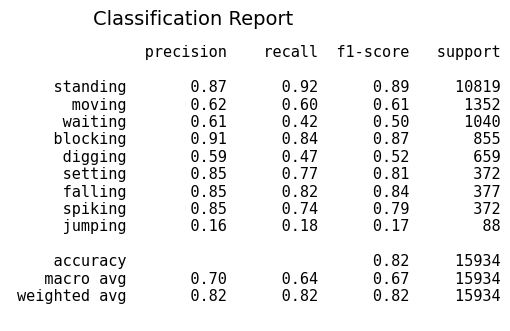

In [35]:
display_classification_report(y_true, y_pred, model_config.classes_names)

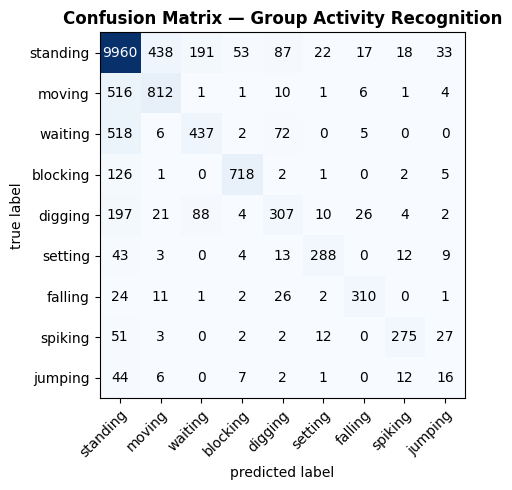

In [36]:
display_confusion_matrix(y_true, y_pred, model_config.classes_names)

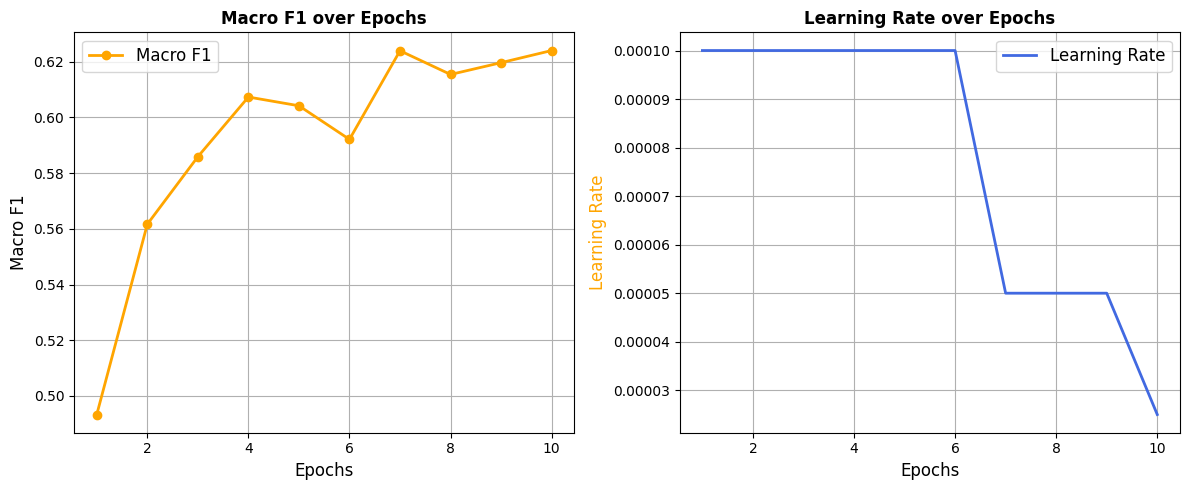

In [37]:
plot_macro_f1_and_lr(epochs, macro_f1, lr_history)

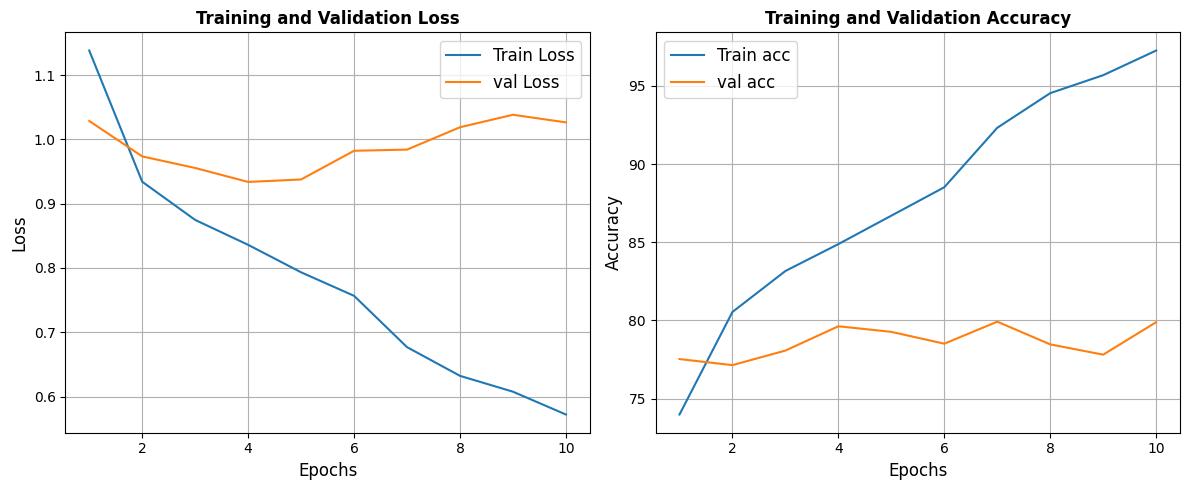

In [38]:
plot_training_curves(epochs,
                          train_losses, val_losses, train_acc, val_acc)

# <a id="Import"></a><div style="background: linear-gradient(to right, #1b5e20, #2e7d32, #388e3c, #43a047, #4caf50); font-family: 'Times New Roman', serif; font-size: 28px; font-weight: bold; text-align: center; border-radius: 15px; padding: 15px; border: 2px solid #ffffff; box-shadow: 0 4px 10px rgba(0, 0, 0, 0.2); -webkit-background-clip: text; -webkit-text-fill-color: transparent;">Thanks & Upvote ❤️</div>